# FBphophet
- [Prophet] (https://facebook.github.io/prophet/) es un software de código abierto lanzado por el equipo de Core Data Science de Facebook.
- Prophet es un procedimiento para pronosticar datos de series de tiempo basado en un modelo aditivo / multiplicativo donde las tendencias no lineales se ajustan a la estacionalidad anual, semanal y diaria, más los efectos de vacaciones.
- Funciona mejor con series de tiempo que tienen fuertes efectos estacionales y varias temporadas de datos históricos.
- Prophet es robusto ante los datos faltantes y los cambios en la tendencia, y generalmente maneja bien los valores atípicos.
- El paquete Prophet proporciona parámetros intuitivos que son fáciles de ajustar.

## Entorno

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

## Dataset

In [4]:
import os

ruta = os.getcwd()
ruta_csv = os.path.join(ruta, 'demanda_limpia.csv')
df = pd.read_csv(ruta_csv)
df.head()

,fecha,demanda,aforo_mensual,anomalia,mes,estacion
0,2010-01-01,35.00,7,0,1,primavera
1,2010-02-01,33.99,7,0,2,invierno
2,2010-03-01,30.00,7,0,3,invierno
3,2010-04-01,36.00,7,0,4,invierno
4,2010-05-01,40.00,8,0,5,otoÃ±o


## Preparación de Datos

In [5]:
df = df.rename(columns={'demanda': 'y', 'fecha':'ds'}) # <-- Prophet requiere que los nombres de las variables en la serie de tiempo sean: y = m3; ds =fehca
df['ds'] = pd.to_datetime(df['ds'])

## Separación
No aplica en FbProphet

## Algoritmo Univariable


### Entrenamiento

In [6]:
from prophet import Prophet

model = Prophet(yearly_seasonality=True, # <-- # Configuramos Prophet con estacionalidad anual (ideal para datos mensuales o estacionales)
                seasonality_mode='multiplicative', # <-- modo multiplicativo si la tendencia o estacionalidad crece proporcionalmente al nivel de la serie
                # changepoint_prior_scale=0.5,  # Valor más alto = mayor flexibilidad ante cambios de tendencia
                # growth = 'logistic'
                )

# model.add_country_holidays(country_name='PE') # <-- Si deseas agregar feriados del pais

model.fit(df)


Importing plotly failed. Interactive plots will not work.
c:\Users\games\OneDrive\DS\Clases\Portafolio\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
11:24:38 - cmdstanpy - INFO - Chain [1] start processing
11:24:41 - cmdstanpy - INFO - Chain [1] done processing


#### Predicciones

In [7]:
# Creamos el dataframe futuro. Como tus datos parecen mensuales ('MS' = Inicio de mes), 
periods_to_predict = 12  # Validamos el test y proyectamos 12 meses más hacia el futuro o según el periodo que necesites predecir
future = model.make_future_dataframe(periods=periods_to_predict, freq='MS')
future.tail(12)

,ds
202,2026-11-01
203,2026-12-01
204,2027-01-01
205,2027-02-01
206,2027-03-01
207,2027-04-01
208,2027-05-01
209,2027-06-01
210,2027-07-01
211,2027-08-01


In [8]:
# Agregar la columna 'cap' con el mismo límite máximo
# future['cap'] = 89 # <-- Usar solo si se va a poner un limite superior que no se puede alcalzar: # Ajusta este valor según el límite máximo de tu serie

forecast = model.predict(future)
forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail(12)

,ds,yhat,yhat_lower,yhat_upper
202,2026-11-01,75.407369,65.449694,86.128895
203,2026-12-01,90.033346,79.203634,101.002539
204,2027-01-01,64.066874,54.050688,75.230242
205,2027-02-01,59.769707,49.067561,70.652888
206,2027-03-01,59.179722,47.611712,69.032254
207,2027-04-01,63.267722,52.428711,74.291302
208,2027-05-01,72.681043,61.891964,82.494775
209,2027-06-01,73.105388,61.938503,84.158707
210,2027-07-01,73.459703,62.961164,85.090281
211,2027-08-01,64.253673,53.486643,74.915784


#### Evaluación

In [9]:
from sklearn.metrics import (mean_squared_error, r2_score, mean_absolute_error, median_absolute_error, mean_squared_log_error)

def evaluate_forecast(y_true, y_pred):
    results = pd.DataFrame({
        'r2_score': [r2_score(y_true, y_pred)],
        'mean_absolute_error': [mean_absolute_error(y_true, y_pred)],
        'median_absolute_error': [median_absolute_error(y_true, y_pred)],
        'mse': [mean_squared_error(y_true, y_pred)],
        'rmse': [np.sqrt(mean_squared_error(y_true, y_pred))]
    })
    return results


##### Evaluación de Predicción

In [10]:
# 1. Asegurar que las fechas tengan el mismo tipo de dato


In [11]:
# Extraemos las predicciones correspondientes únicamente al periodo de validación
# Alineamos por fecha para comparar exactamente los valores reales vs predichos
eval_forecast = forecast[forecast['ds'].isin(df['ds'])].copy()
predictions_valid = eval_forecast['yhat'].values
actuals_valid = df['y'].values

In [12]:
# Calcular métricas de error en validación
metrics_results = evaluate_forecast(actuals_valid, predictions_valid)
print("\n--- Métricas de Evaluación en Validación ---")
metrics_results


--- Métricas de Evaluación en Validación ---


,r2_score,mean_absolute_error,median_absolute_error,mse,rmse
0,0.594127,6.2223,4.133377,70.316974,8.385522


In [13]:
evaluate_forecast(actuals_valid[-12:], predictions_valid[-12:]) # valid. Mide el error únicamente en los últimos 36 meses

,r2_score,mean_absolute_error,median_absolute_error,mse,rmse
0,0.605852,7.828251,7.958218,76.494851,8.746133


##### Grafica para la Validacion

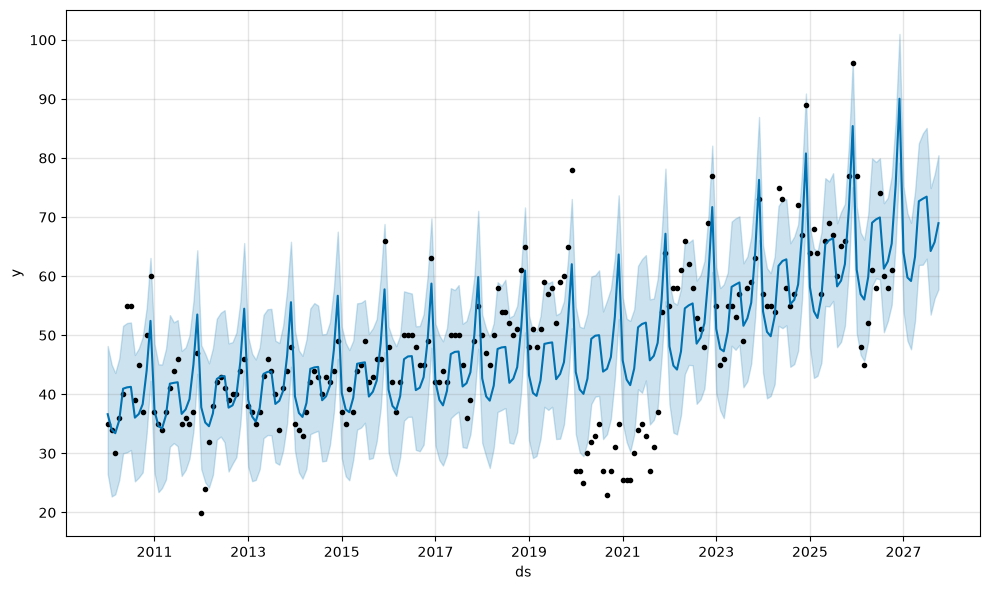

In [14]:
fig1 = model.plot(forecast)
# plt.axhline(y=0, color='red') # <-- Dibuja la linea roja si quieres poner un limite



##### Puntos de Cambio de Tendencia

Prophet coloca de forma automática potenciales puntos de cambio distribuidos en el primer 80% de las fechas históricas de tu serie temporal.

Selección por regularización: El algoritmo evalúa en cuáles de esos puntos ocurre un cambio de pendiente estadísticamente relevante según la penalización estándar (changepoint_prior_scale=0.05 por defecto) y marca los más importantes.

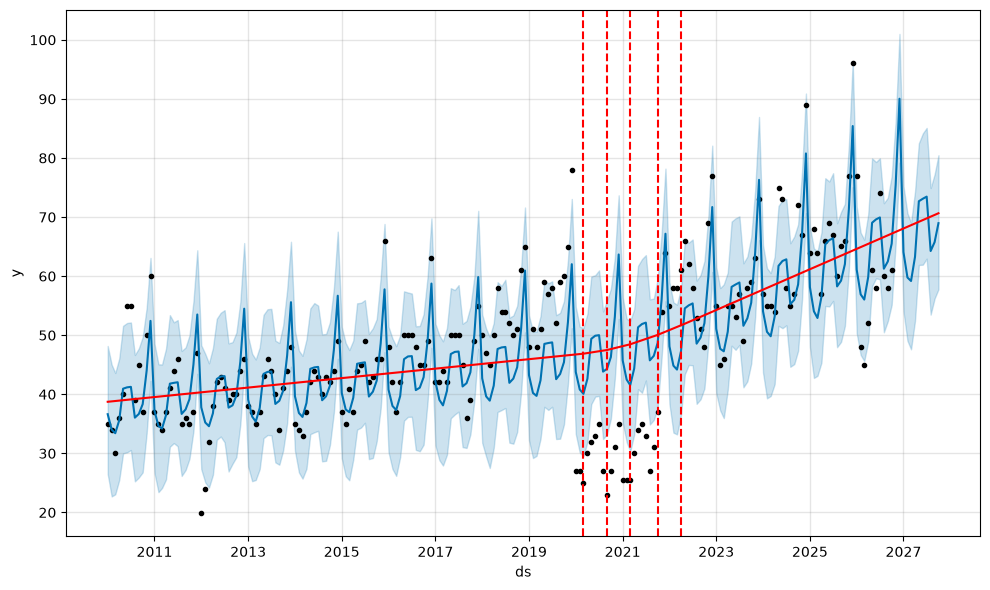

In [15]:
from prophet.plot import add_changepoints_to_plot
fig = model.plot(forecast)
a = add_changepoints_to_plot(fig.gca(), model, forecast)


##### Gráfico de Punto de Cambio
En este ejemplo, no figura el punto de cambio

11:24:46 - cmdstanpy - INFO - Chain [1] start processing
11:24:46 - cmdstanpy - INFO - Chain [1] done processing
11:24:46 - cmdstanpy - ERROR - Chain [1] error: code '1' Operation not permitted
Optimization terminated abnormally. Falling back to Newton.
11:24:46 - cmdstanpy - INFO - Chain [1] start processing
11:24:46 - cmdstanpy - INFO - Chain [1] done processing


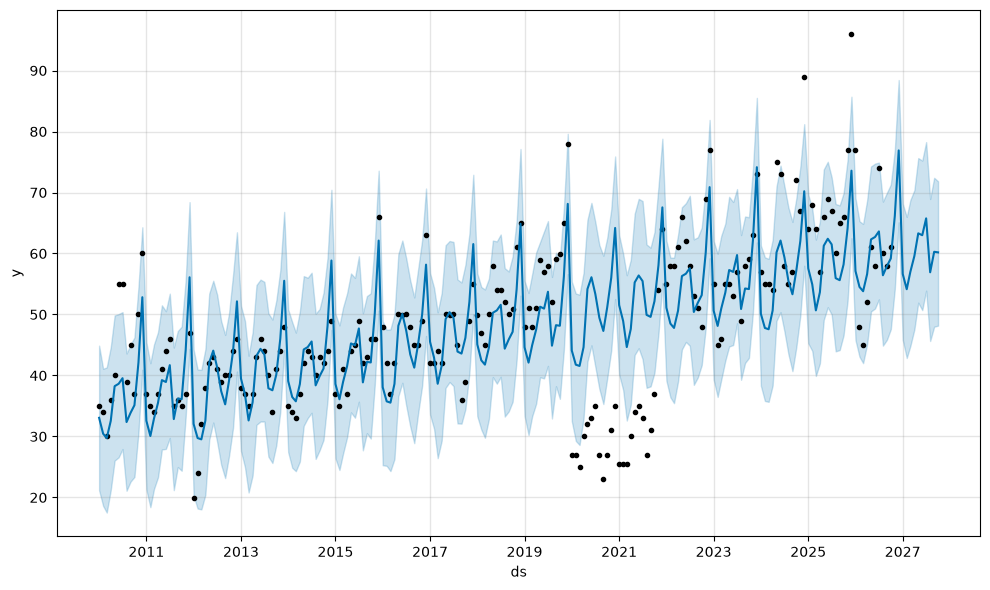

In [16]:
model = Prophet(changepoints=['2026-01-01'])
forecast = model.fit(df).predict(future)
fig = model.plot(forecast)

##### Gráfica de Descomposición de Componentes

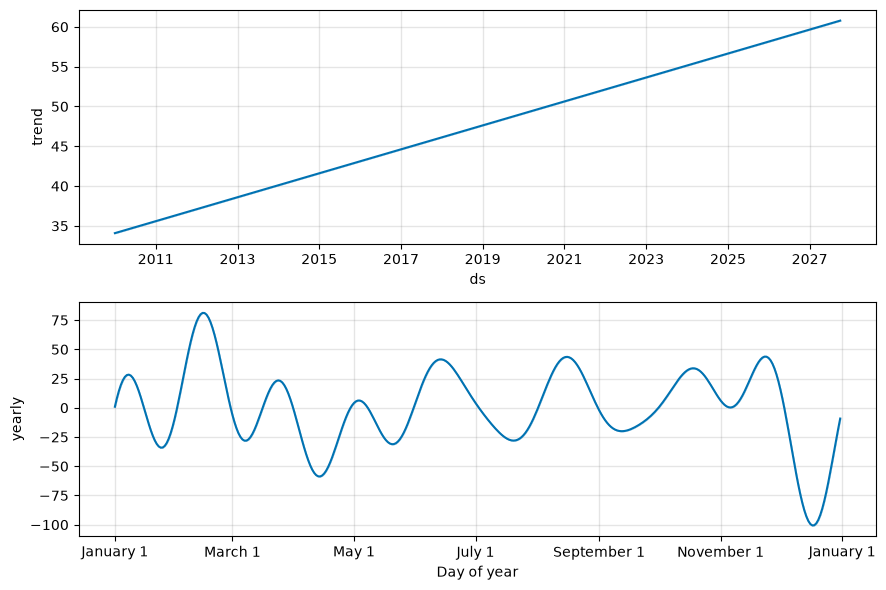

In [17]:
# Gráfica de componentes (Tendencia y Estacionalidad)
fig_components = model.plot_components(forecast)
plt.show()

### Validación Cruzada

In [18]:
from prophet.diagnostics import cross_validation

# Equivalencias aproximadas en días:
# 1 mes = 30 días (aprox)
# 2 años = 730 días
# 6 meses = 180 días
# 12 meses = 365 días

df_cv = cross_validation(
    model,                  # Usando tu variable 'model'
    initial='730 days',     # Ej: 2 años de entrenamiento inicial
    period='180 days',      # Ej: Realizar un corte cada 6 meses ('6M')
    horizon='365 days'      # Ej: Pronosticar los siguientes 12 meses ('12M')
)

  0%|          | 0/28 [00:00<?, ?it/s]11:24:47 - cmdstanpy - INFO - Chain [1] start processing
11:24:47 - cmdstanpy - INFO - Chain [1] done processing
  4%|▎         | 1/28 [00:00<00:07,  3.56it/s]11:24:47 - cmdstanpy - INFO - Chain [1] start processing
11:24:47 - cmdstanpy - INFO - Chain [1] done processing
  7%|▋         | 2/28 [00:00<00:07,  3.53it/s]11:24:48 - cmdstanpy - INFO - Chain [1] start processing
11:24:48 - cmdstanpy - INFO - Chain [1] done processing
 11%|█         | 3/28 [00:00<00:06,  3.78it/s]11:24:48 - cmdstanpy - INFO - Chain [1] start processing
11:24:48 - cmdstanpy - INFO - Chain [1] done processing
 14%|█▍        | 4/28 [00:01<00:06,  3.48it/s]11:24:48 - cmdstanpy - INFO - Chain [1] start processing
11:24:48 - cmdstanpy - INFO - Chain [1] done processing
 18%|█▊        | 5/28 [00:01<00:06,  3.58it/s]11:24:48 - cmdstanpy - INFO - Chain [1] start processing
11:24:49 - cmdstanpy - INFO - Chain [1] done processing
 21%|██▏       | 6/28 [00:01<00:06,  3.62it/s]11:24:49

In [19]:
df_cv.head()


,ds,yhat,yhat_lower,yhat_upper,y,cutoff
0,2012-07-01,45.882499,41.383370,50.370647,41.02,2012-06-11
1,2012-08-01,24.646694,20.490019,28.879525,39.00,2012-06-11
2,2012-09-01,41.498587,37.272664,46.023166,40.00,2012-06-11
3,2012-10-01,17.018781,12.912594,21.347952,40.00,2012-06-11
4,2012-11-01,46.095416,41.542707,50.188670,44.00,2012-06-11


In [20]:
from prophet.diagnostics import register_performance_metric, rolling_mean_by_h, performance_metrics

@register_performance_metric
def mase(df, w):
    """Mean absolute scale error"""
    e = (df['y'] - df['yhat'])
    d = np.abs(np.diff(df['y'])).sum() / (df['y'].shape[0] - 1)
    se = np.abs(e / d)
    if w < 0:
        return pd.DataFrame({'horizon': df['horizon'], 'mase': se})
    return rolling_mean_by_h(
        x=se.values, h=df['horizon'].values, w=w, name='mase'
    )

df_mase = performance_metrics(df_cv, metrics=['mase'])
df_mase.head()

,horizon,mase
0,37 days,0.643425
1,39 days,0.630519
2,40 days,0.644783
3,41 days,0.626994
4,42 days,0.628097


In [21]:
from prophet.diagnostics import performance_metrics
df_p = performance_metrics(df_cv)
df_p.head()

,horizon,mse,rmse,mae,mape,mdape,smape,coverage
0,37 days,148.973361,12.205464,9.380557,0.207938,0.119863,0.188770,0.515152
1,39 days,141.126694,11.879676,9.192405,0.196456,0.119863,0.186008,0.515152
2,40 days,143.561628,11.981721,9.400352,0.199354,0.127785,0.189286,0.515152
3,41 days,135.529004,11.641693,9.141013,0.189722,0.127785,0.182958,0.530303
4,42 days,132.203948,11.497998,9.157086,0.184061,0.127785,0.181256,0.515152


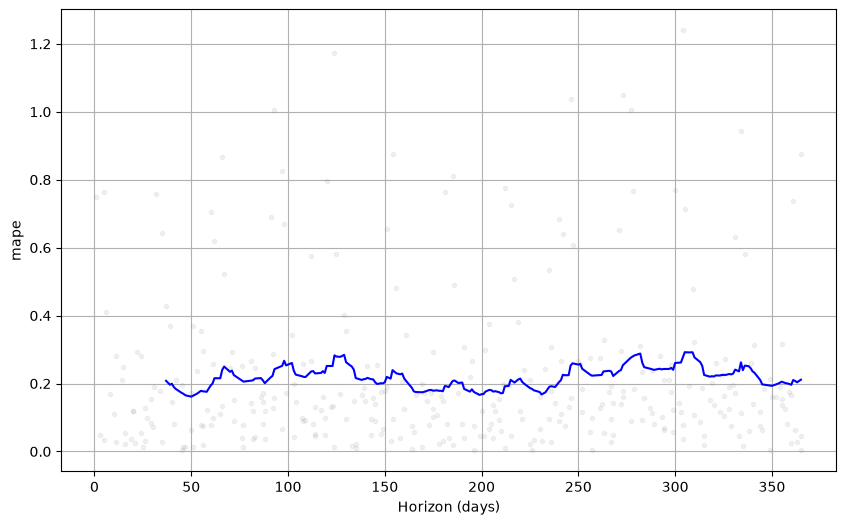

In [22]:
from prophet.plot import plot_cross_validation_metric
fig = plot_cross_validation_metric(df_cv, metric='mape')

### Hiperparámetros

In [23]:
# Define las fechas de corte según el rango de tu DataFrame (df)
cutoffs = pd.to_datetime(['2010-02-01', '2026-09-01'])

In [24]:
import itertools

param_grid = {  
    'changepoint_prior_scale': [0.01, 0.05, 0.1],
    'seasonality_prior_scale': [0.1, 1.0, 10.0],
}

# Generate all combinations of parameters
all_params = [dict(zip(param_grid.keys(), v)) for v in itertools.product(*param_grid.values())]
rmses = []  # Store the RMSEs for each params here

# Use cross validation to evaluate all parameters
for params in all_params:
    m = Prophet(**params).fit(df)  # Fit model with given params
    df_cv = cross_validation(m, cutoffs=cutoffs, horizon='30 days', parallel="processes")
    df_p = performance_metrics(df_cv, rolling_window=1)
    rmses.append(df_p['rmse'].values[0])

# Find the best parameters
tuning_results = pd.DataFrame(all_params)
tuning_results['rmse'] = rmses
print(tuning_results)

11:24:58 - cmdstanpy - INFO - Chain [1] start processing
11:24:58 - cmdstanpy - INFO - Chain [1] done processing
Seasonality has period of 365.25 days which is larger than initial window. Consider increasing initial.
11:25:05 - cmdstanpy - INFO - Chain [1] start processing
11:25:05 - cmdstanpy - INFO - Chain [1] done processing
Seasonality has period of 365.25 days which is larger than initial window. Consider increasing initial.
11:25:08 - cmdstanpy - INFO - Chain [1] start processing
11:25:08 - cmdstanpy - INFO - Chain [1] done processing
Seasonality has period of 365.25 days which is larger than initial window. Consider increasing initial.
11:25:11 - cmdstanpy - INFO - Chain [1] start processing
11:25:11 - cmdstanpy - INFO - Chain [1] done processing
Seasonality has period of 365.25 days which is larger than initial window. Consider increasing initial.
11:25:15 - cmdstanpy - INFO - Chain [1] start processing
11:25:15 - cmdstanpy - INFO - Chain [1] done processing
Seasonality has per

   changepoint_prior_scale  seasonality_prior_scale        rmse
0                     0.01                      0.1    1.977948
1                     0.01                      1.0   24.570958
2                     0.01                     10.0  118.523729
3                     0.05                      0.1    3.283783
4                     0.05                      1.0   68.250102
5                     0.05                     10.0   63.307453
6                     0.10                      0.1    5.312372
7                     0.10                      1.0    5.641004
8                     0.10                     10.0  670.251841
